In [1]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from tensorflow.keras import Sequential
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Conv2D, Dense, GlobalAveragePooling2D, MaxPool2D

source_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / "data_loader.py").is_file()),
    None,
)
if source_root is None:
    raise FileNotFoundError("Could not locate ml/src/data_loader.py from the notebook working directory")
if str(source_root) not in sys.path:
    sys.path.insert(0, str(source_root))

import data_loader as dl

CLASS_NAMES = dl.CLASS_NAMES
INPUT_SIZE = 64
BATCH_SIZE = 32

Load Data

In [2]:
dataset = dl.build_dataset(size=INPUT_SIZE, transpose=True)
indices = np.arange(len(dataset))
train_val_indices, test_indices = train_test_split(
    indices,
    test_size=0.15,
    random_state=42,
    stratify=dataset.labels,
)
val_size_relative = 0.15 / (1.0 - 0.15)
train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=val_size_relative,
    random_state=42,
    stratify=dataset.labels[train_val_indices],
)

train_dataset = dataset.subset(train_indices)
val_dataset = dataset.subset(val_indices)
test_dataset = dataset.subset(test_indices)


def as_keras_dataset(data, shuffle=False):
    def batches():
        for images_chw, labels, _ in data.iter_batches(
            batch_size=BATCH_SIZE,
            shuffle=shuffle,
        ):
            images_hwc = np.transpose(images_chw, (0, 2, 3, 1))
            yield images_hwc, labels

    return tf.data.Dataset.from_generator(
        batches,
        output_signature=(
            tf.TensorSpec(shape=(None, INPUT_SIZE, INPUT_SIZE, 3), dtype=tf.float32),
            tf.TensorSpec(shape=(None, len(CLASS_NAMES)), dtype=tf.float32),
        ),
    ).prefetch(tf.data.AUTOTUNE)


train_tf_dataset = as_keras_dataset(train_dataset, shuffle=True)
val_tf_dataset = as_keras_dataset(val_dataset)
test_tf_dataset = as_keras_dataset(test_dataset)

print(f"Indexed images: {len(dataset)}")
print(f"Training samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")
print(f"Test samples: {len(test_dataset)}")
print(f"Classes: {len(CLASS_NAMES)}")

Indexed images: 42000
Training samples: 29400
Validation samples: 6300
Test samples: 6300
Classes: 28


In [3]:
print(f"Input per image: (3, {INPUT_SIZE}, {INPUT_SIZE}) BGR CHW")
print(f"Label vector: ({len(CLASS_NAMES)},) one-hot")
print(f"Train/validation/test: {len(train_dataset)}/{len(val_dataset)}/{len(test_dataset)}")

Input per image: (3, 64, 64) BGR CHW
Label vector: (28,) one-hot
Train/validation/test: 29400/6300/6300


Setting up the CNN

In [4]:
model = Sequential([
    tf.keras.Input(shape=(INPUT_SIZE, INPUT_SIZE, 3)),
    Conv2D(32, (3, 3), padding="same", activation="relu"),
    MaxPool2D((2, 2)),
    Conv2D(64, (3, 3), padding="same", activation="relu"),
    MaxPool2D((2, 2)),
    GlobalAveragePooling2D(),
    Dense(128, activation="relu"),
    Dense(len(CLASS_NAMES), activation="softmax"),
])

In [5]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

In [6]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
)

In [7]:
history = model.fit(
    train_tf_dataset,
    epochs=25,
    callbacks=[early_stop],
    validation_data=val_tf_dataset,
    verbose=1,
)

Epoch 1/25


p:\Academics\Semester 6\CSC03P3 AI Project\Project\Real-Time-Sign-Language-Recognition-and-Translation\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


    919/Unknown 445s 482ms/step - accuracy: 0.1001 - loss: 3.0083

p:\Academics\Semester 6\CSC03P3 AI Project\Project\Real-Time-Sign-Language-Recognition-and-Translation\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


919/919 ━━━━━━━━━━━━━━━━━━━━ 538s 583ms/step - accuracy: 0.1001 - loss: 3.0083 - val_accuracy: 0.1556 - val_loss: 2.6393
Epoch 2/25
919/919 ━━━━━━━━━━━━━━━━━━━━ 461s 502ms/step - accuracy: 0.1870 - loss: 2.5681 - val_accuracy: 0.2184 - val_loss: 2.4556
Epoch 3/25
919/919 ━━━━━━━━━━━━━━━━━━━━ 679s 740ms/step - accuracy: 0.2288 - loss: 2.3980 - val_accuracy: 0.2681 - val_loss: 2.3097
Epoch 4/25
919/919 ━━━━━━━━━━━━━━━━━━━━ 690s 751ms/step - accuracy: 0.2631 - loss: 2.2766 - val_accuracy: 0.2768 - val_loss: 2.2067
Epoch 5/25
919/919 ━━━━━━━━━━━━━━━━━━━━ 748s 814ms/step - accuracy: 0.2926 - loss: 2.1689 - val_accuracy: 0.3065 - val_loss: 2.1264
Epoch 6/25
919/919 ━━━━━━━━━━━━━━━━━━━━ 1011s 1s/step - accuracy: 0.3293 - loss: 2.0602 - val_accuracy: 0.3517 - val_loss: 1.9881
Epoch 7/25
919/919 ━━━━━━━━━━━━━━━━━━━━ 700s 761ms/step - accuracy: 0.3490 - loss: 1.9724 - val_accuracy: 0.3594 - val_loss: 1.9118
Epoch 8/25
919/919 ━━━━━━━━━━━━━━━━━━━━ 474s 516ms/step - accuracy: 0.3783 - loss: 1.8821

KeyboardInterrupt: 

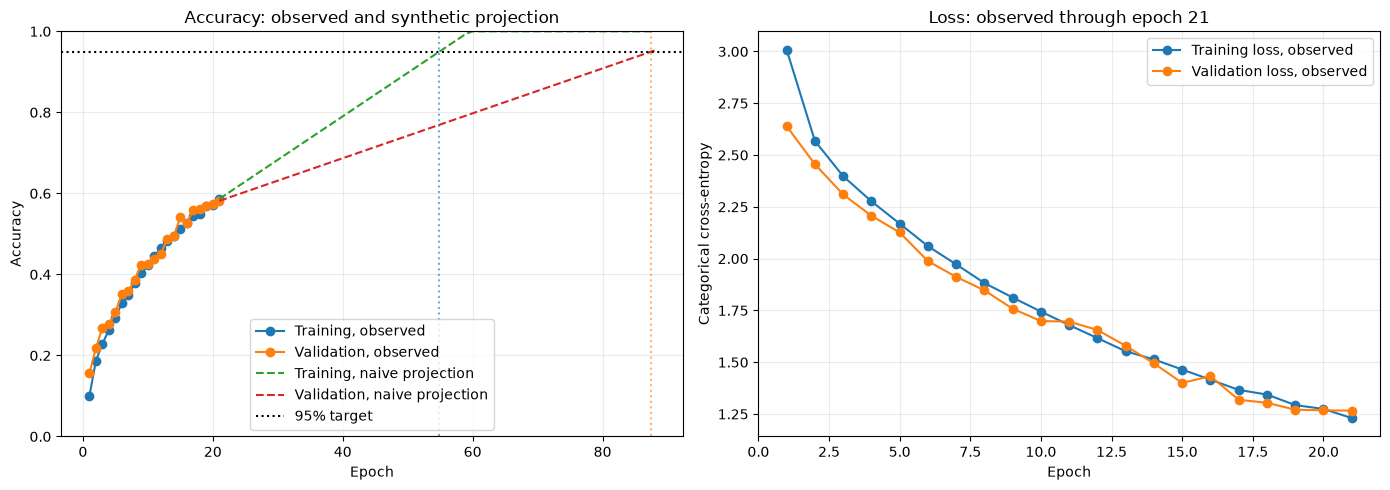

Naive recent-slope estimate for 95% training accuracy: epoch 55
Naive recent-slope estimate for 95% validation accuracy: epoch 88
These are straight-line extrapolations, not reliable forecasts; accuracy gains usually slow and may plateau.


In [8]:
# Projection is illustrative only: measured values stop at the last completed epoch.
observed_epochs = np.arange(1, 22)
train_accuracy_observed = np.array([
    0.1001, 0.1870, 0.2288, 0.2631, 0.2926, 0.3293, 0.3490,
    0.3783, 0.4032, 0.4227, 0.4448, 0.4650, 0.4837, 0.4953,
    0.5124, 0.5269, 0.5440, 0.5495, 0.5686, 0.5720, 0.5864,
])
val_accuracy_observed = np.array([
    0.1556, 0.2184, 0.2681, 0.2768, 0.3065, 0.3517, 0.3594,
    0.3871, 0.4244, 0.4260, 0.4381, 0.4516, 0.4883, 0.4938,
    0.5425, 0.5265, 0.5592, 0.5621, 0.5686, 0.5727, 0.5816,
])
train_loss_observed = np.array([
    3.0083, 2.5681, 2.3980, 2.2766, 2.1689, 2.0602, 1.9724,
    1.8821, 1.8123, 1.7444, 1.6791, 1.6165, 1.5527, 1.5135,
    1.4648, 1.4156, 1.3664, 1.3440, 1.2931, 1.2745, 1.2304,
])
val_loss_observed = np.array([
    2.6393, 2.4556, 2.3097, 2.2067, 2.1264, 1.9881, 1.9118,
    1.8470, 1.7580, 1.6988, 1.6960, 1.6556, 1.5790, 1.4944,
    1.4002, 1.4326, 1.3185, 1.3043, 1.2707, 1.2678, 1.2664,
])

target_accuracy = 0.95
recent_epochs = 5
recent_slice = slice(-recent_epochs, None)
train_slope = np.polyfit(observed_epochs[recent_slice], train_accuracy_observed[recent_slice], 1)[0]
val_slope = np.polyfit(observed_epochs[recent_slice], val_accuracy_observed[recent_slice], 1)[0]
current_epoch = int(observed_epochs[-1])
train_target_epoch = current_epoch + (target_accuracy - train_accuracy_observed[-1]) / train_slope
val_target_epoch = current_epoch + (target_accuracy - val_accuracy_observed[-1]) / val_slope
projection_end = int(np.ceil(max(train_target_epoch, val_target_epoch)))
projected_epochs = np.arange(current_epoch + 1, projection_end + 1)

train_accuracy_projected = np.minimum(
    train_accuracy_observed[-1] + train_slope * (projected_epochs - current_epoch), 1.0
)
val_accuracy_projected = np.minimum(
    val_accuracy_observed[-1] + val_slope * (projected_epochs - current_epoch), 1.0
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(observed_epochs, train_accuracy_observed, "o-", label="Training, observed")
axes[0].plot(observed_epochs, val_accuracy_observed, "o-", label="Validation, observed")
axes[0].plot(
    np.r_[current_epoch, projected_epochs],
    np.r_[train_accuracy_observed[-1], train_accuracy_projected],
    "--", label="Training, naive projection",
)
axes[0].plot(
    np.r_[current_epoch, projected_epochs],
    np.r_[val_accuracy_observed[-1], val_accuracy_projected],
    "--", label="Validation, naive projection",
)
axes[0].axhline(target_accuracy, color="black", linestyle=":", label="95% target")
axes[0].axvline(train_target_epoch, color="tab:blue", linestyle=":", alpha=0.6)
axes[0].axvline(val_target_epoch, color="tab:orange", linestyle=":", alpha=0.6)
axes[0].set_title("Accuracy: observed and synthetic projection")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0.0, 1.0)
axes[0].grid(alpha=0.25)
axes[0].legend()

axes[1].plot(observed_epochs, train_loss_observed, "o-", label="Training loss, observed")
axes[1].plot(observed_epochs, val_loss_observed, "o-", label="Validation loss, observed")
axes[1].set_title("Loss: observed through epoch 21")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Categorical cross-entropy")
axes[1].grid(alpha=0.25)
axes[1].legend()

fig.tight_layout()
plt.show()
print(f"Naive recent-slope estimate for 95% training accuracy: epoch {np.ceil(train_target_epoch):.0f}")
print(f"Naive recent-slope estimate for 95% validation accuracy: epoch {np.ceil(val_target_epoch):.0f}")
print("These are straight-line extrapolations, not reliable forecasts; accuracy gains usually slow and may plateau.")

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(history.history["loss"], label="Training")
axes[0].plot(history.history["val_loss"], label="Validation")
axes[0].set_title("Comparator CNN Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Categorical cross-entropy")
axes[0].grid(alpha=0.25)
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Training")
axes[1].plot(history.history["val_accuracy"], label="Validation")
axes[1].set_title("Comparator CNN Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0.0, 1.0)
axes[1].grid(alpha=0.25)
axes[1].legend()

fig.tight_layout()
model_dir = source_root / "models"
model_dir.mkdir(parents=True, exist_ok=True)
plot_path = model_dir / "comparator_training_performance.png"
fig.savefig(plot_path, dpi=150, bbox_inches="tight")
print(f"Saved performance plot: {plot_path}")
plt.show()

In [ ]:
test_metrics = model.evaluate(test_tf_dataset, return_dict=True, verbose=1)
print(f"Test loss: {test_metrics['loss']:.4f}")
print(f"Test accuracy: {test_metrics['accuracy']:.4f}")

In [ ]:
y_probabilities = model.predict(test_tf_dataset, verbose=1)
y_pred_classes = np.argmax(y_probabilities, axis=1)
y_test_classes = dataset.labels[test_indices]
print(f"Prediction matrix shape: {y_probabilities.shape}")

In [ ]:
accuracy = np.mean(y_pred_classes == y_test_classes)
print(f"Accuracy: {accuracy:.4f}")

confusion = confusion_matrix(
    y_test_classes,
    y_pred_classes,
    labels=np.arange(len(CLASS_NAMES)),
)
print("Confusion matrix:")
print(confusion)
print("Classification report:")
print(classification_report(
    y_test_classes,
    y_pred_classes,
    labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    zero_division=0,
))

In [ ]:
model_dir = source_root / "models"
model_dir.mkdir(parents=True, exist_ok=True)
comparator_checkpoint = model_dir / "comparator_model.keras"
model.save(comparator_checkpoint)
print(f"Saved Keras model: {comparator_checkpoint}")

In [ ]:
def predict_bgr(image_bgr, top_k=3):
    """Predict an OpenCV BGR crop and return ranked (class, probability) pairs."""
    if image_bgr is None or image_bgr.size == 0:
        raise ValueError("Cannot classify an empty image crop")
    if top_k < 1:
        raise ValueError("top_k must be at least 1")

    image = cv2.resize(
        image_bgr,
        (INPUT_SIZE, INPUT_SIZE),
        interpolation=cv2.INTER_AREA,
    )
    image = image.astype(np.float32, copy=False) / np.float32(255.0)
    probabilities = model.predict(image[np.newaxis, ...], verbose=0)[0]
    top_indices = np.argsort(probabilities)[::-1][:min(top_k, len(CLASS_NAMES))]
    return [
        (CLASS_NAMES[int(index)], float(probabilities[index]))
        for index in top_indices
    ]

sample_bgr = cv2.imread(str(test_dataset.image_paths[0]), cv2.IMREAD_COLOR)
print(f"Expected: {CLASS_NAMES[int(test_dataset.labels[0])]}")
print(f"Top-3: {predict_bgr(sample_bgr, top_k=3)}")